# Case-Study Activity: The I-94 "Traffic Pulse"
**UE24CS342AA9 · Unit 3 · PPT 5: Animation, Motion and Temporal Visualization · Duration: ~28 minutes**

**Dataset:** Metro Interstate Traffic Volume (Kaggle) — https://www.kaggle.com/datasets/anshtanwar/metro-interstate-traffic-volume
Hourly westbound traffic on Interstate 94 between Minneapolis and St Paul (2012–2018), with weather and holidays.

---
### 📋 The case
You have just joined the **Minnesota Department of Transportation (MnDOT)** as a data-visualization analyst. Your manager needs two things:

1. **For the road-works engineers:** evidence for *when* a daytime lane closure on I-94 would disrupt the fewest drivers.
2. **For the public lobby screen:** an animated *"Traffic Pulse"* that shows how a typical day's traffic changes through the year.

A vendor has also offered to cut storage costs by **recording traffic only once every 25 hours**. You need to advise on that too.

Each part has **💻 coding tasks** (checked automatically) and **✍️ reflection questions** (write 2–3 sentences each).



## Part 0 — Setup (1 min): run both cells, don't edit

In [1]:
%pip install -q kagglehub plotly

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, glob, calendar, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, plotly.express as px
warnings.filterwarnings("ignore")

if os.path.exists("Metro_Interstate_Traffic_Volume.csv"):
    path = "Metro_Interstate_Traffic_Volume.csv"
else:
    import kagglehub
    path = sorted(glob.glob(os.path.join(kagglehub.dataset_download("anshtanwar/metro-interstate-traffic-volume"), "**", "*.csv"), recursive=True))[0]

raw = pd.read_csv(path); raw.columns = raw.columns.str.strip().str.lower()
for kw in [dict(format="%Y-%m-%d %H:%M:%S"), dict(format="%d-%m-%Y %H:%M"), dict(format="%d-%m-%Y %H:%M:%S"), dict(format="mixed", dayfirst=True)]:
    t = pd.to_datetime(raw["date_time"], errors="coerce", **kw)
    if t.notna().mean() > 0.99: raw["date_time"] = t; break
raw["holiday"] = raw["holiday"].fillna("None").astype(str).str.strip().replace({"": "None", "nan": "None"})
print(f"raw: {len(raw):,} rows, {raw.date_time.min()} → {raw.date_time.max()}")
raw.head()

100%|██████████| 414k/414k [00:00<00:00, 743kB/s]

Extracting files...


raw: 48,204 rows, 2012-10-02 09:00:00 → 2018-09-30 23:00:00


,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time
0,5545,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00
1,4516,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00
2,4767,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00
3,5026,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00
4,4918,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00


In [3]:
# ===================== AUTO-CHECKER — run, do not edit =====================
_S = {}
def _r(k, ok, good, hint):
    _S[k] = bool(ok); print(("✅ " + good) if ok else ("❌ Not yet — hint: " + hint))
def _exp_clean():
    t = raw.drop_duplicates("date_time").sort_values("date_time").set_index("date_time")
    h = t.loc[t.holiday != "None", "holiday"]; hd = pd.Series(h.values, index=h.index.normalize()); hd = hd[~hd.index.duplicated()]
    t["holiday_day"] = t.index.normalize().map(hd).fillna("None"); return t
_T = _exp_clean()

def check_A(n_dups, tr, modal_interval_h, longest_gap_days):
    g = _T.index.to_series().diff().dropna()
    if n_dups != raw.date_time.duplicated().sum(): return _r("A", 0, "", "count duplicated timestamps in raw['date_time'] with .duplicated().sum().")
    if not (isinstance(tr, pd.DataFrame) and len(tr) == len(_T) and tr.index.is_monotonic_increasing):
        return _r("A", 0, "", "drop duplicate timestamps, sort, and set 'date_time' as the index.")
    if abs(modal_interval_h - g.mode()[0].total_seconds() / 3600) > 1e-9: return _r("A", 0, "", "take the MODE of the differences between consecutive timestamps, in hours.")
    if abs(longest_gap_days - g.max().total_seconds() / 86400) > 0.01: return _r("A", 0, "", "longest gap = max of the differences, converted to days.")
    _r("A", 1, f"Part A correct — modal interval {modal_interval_h:g} h, longest gap {longest_gap_days:.0f} days.", "")

def check_B(nyquist_max_interval, aliased_period, apparent_period_25h):
    try:
        ok1 = abs(nyquist_max_interval(24) - 12) < 1e-9 and abs(nyquist_max_interval(15) - 7.5) < 1e-9
        ok2 = abs(aliased_period(50, 60) - 300) < 1e-6 and abs(aliased_period(24, 23) - 552) < 1e-6 and abs(aliased_period(24, 25) - 600) < 1e-6
    except Exception as e: return _r("B", 0, "", f"error: {e}")
    if not ok1: return _r("B", 0, "", "Nyquist: fs > 2f, so the sampling interval must be < period / 2.")
    if not ok2: return _r("B", 0, "", "aliased frequency = |f − fs| (f = 1/period, fs = 1/interval); period = 1 / that.")
    if abs(apparent_period_25h - 600) > 1e-6: return _r("B", 0, "", "call your aliased_period with the 24-h cycle and a 25-h interval.")
    _r("B", 1, "Part B correct — a 24-h cycle sampled every 25 h looks like a 600-h (25-day) cycle!", "")

def check_C(daily, ma7_centred, ma7_trailing, points_per_pixel):
    d = _T["traffic_volume"].loc["2017"].resample("D").sum(min_count=1)
    if not (isinstance(daily, pd.Series) and len(daily) == len(d) and np.allclose(daily.fillna(-1), d.fillna(-1))):
        return _r("C", 0, "", "daily = tr['traffic_volume'].loc['2017'].resample('D').sum(min_count=1).")
    if not np.allclose(ma7_centred.fillna(-1), d.rolling(7, center=True).mean().fillna(-1)): return _r("C", 0, "", "centred MA: .rolling(7, center=True).mean().")
    if not np.allclose(ma7_trailing.fillna(-1), d.rolling(7).mean().fillna(-1)): return _r("C", 0, "", "trailing MA: .rolling(7).mean() (no center).")
    if abs(points_per_pixel - len(_T.loc["2017"]) / 1000) > 1e-6: return _r("C", 0, "", "number of hourly rows in 2017 divided by 1000 px.")
    _r("C", 1, f"Part C correct — hourly 2017 on 1000 px = {points_per_pixel:.1f} points per pixel.", "")

def check_D(weekday_profile, holiday_profile, best_closure_hour):
    w = _T[(_T.index.dayofweek < 5) & (_T.holiday_day == "None")].groupby(_T.index.hour[(_T.index.dayofweek < 5) & (_T.holiday_day == "None")])["traffic_volume"].mean()
    h = _T[_T.holiday_day != "None"]; h = h.groupby(h.index.hour)["traffic_volume"].mean()
    try:
        if not np.allclose(np.asarray(weekday_profile), w.values): return _r("D", 0, "", "weekday = Mon–Fri (dayofweek < 5) AND holiday_day == 'None'; then group by hour and take the mean.")
        if not np.allclose(np.asarray(holiday_profile), h.values): return _r("D", 0, "", "holiday rows: holiday_day != 'None'; group by hour; mean.")
    except Exception as e: return _r("D", 0, "", f"error: {e}")
    if best_closure_hour != int(w.loc[9:15].idxmin()): return _r("D", 0, "", "restrict weekday_profile to hours 9–15 (.loc[9:15]) and take .idxmin().")
    _r("D", 1, f"Part D correct — the quietest daytime start hour on normal weekdays is {best_closure_hour}:00.", "")

def check_E(frame_budget_ms, smoothstep, n_frames, duration_s, compression, fig):
    try:
        ok1 = abs(frame_budget_ms(60) - 1000/60) < 1e-9 and abs(frame_budget_ms(24) - 1000/24) < 1e-9
        ok2 = abs(smoothstep(0.25) - 0.15625) < 1e-9 and smoothstep(0) == 0 and abs(smoothstep(1) - 1) < 1e-9
    except Exception as e: return _r("E", 0, "", f"error: {e}")
    if not ok1: return _r("E", 0, "", "frame budget = 1000 / fps milliseconds.")
    if not ok2: return _r("E", 0, "", "smoothstep s(u) = 3u² − 2u³.")
    if (n_frames, round(duration_s, 6), round(compression)) != (540, 18.0, 4800): return _r("E", 0, "", "24 hours × 0.75 s = duration; × 30 fps = frames; compression = 3600 s of data / 0.75 s.")
    try:
        yr = fig.layout.yaxis.range; nfr = len(fig.frames)
    except Exception: return _r("E", 0, "", "fig must be a plotly express figure with animation_frame.")
    if nfr != 12: return _r("E", 0, "", "use animation_frame='Month' so there is one frame per month (12).")
    if yr is None: return _r("E", 0, "", "fix the y-axis with range_y=[0, 7500] so bars stay comparable across frames (congruence!).")
    _r("E", 1, "Part E correct — 540 frames, 18 s, 4800:1, fixed axis, 12 frames.", "")

def summary():
    for k in "ABCDE": print(f"Part {k}: {'✅' if _S.get(k) else '❌'}")
    print(f"Coding score: {sum(_S.values())}/5   (+ reflection questions, graded by instructor)")
print("Auto-checker ready.")

Auto-checker ready.


---
## Part A — Understand the temporal data 
Before you visualize anything, check the **temporal structure** of the data.

**A1.** Compute:
- `n_dups`: the number of **duplicate timestamps** in `raw` (several weather labels can share an hour)
- `tr`: a clean table with **one row per hour**, sorted, with `date_time` as the **index**
- `modal_interval_h`: the **most common** gap between consecutive rows, in hours
- `longest_gap_days`: the **longest** gap in the record, in days

In [4]:
n_dups = raw["date_time"].duplicated().sum()           # TODO
tr = raw.drop_duplicates("date_time").sort_values("date_time").set_index("date_time")     # TODO: drop duplicate timestamps, sort, set index

gaps = tr.index.to_series().diff().dropna()
modal_interval_h = gaps.mode()[0].total_seconds() / 3600  # TODO: gaps.mode()[0] in hours  (hint: .total_seconds() / 3600)
longest_gap_days = gaps.max().total_seconds() / 86400 # TODO

check_A(n_dups, tr, modal_interval_h, longest_gap_days)

✅ Part A correct — modal interval 1 h, longest gap 308 days.


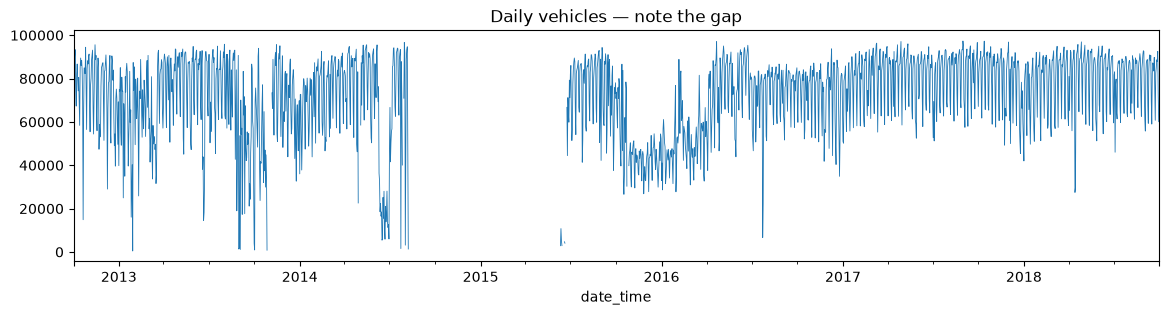

In [5]:
# (given) Holiday names appear only on the midnight row, so spread them to the whole day. Then plot the record.
_h = tr.loc[tr.holiday != "None", "holiday"]; _hd = pd.Series(_h.values, index=_h.index.normalize()); _hd = _hd[~_hd.index.duplicated()]
tr["holiday_day"] = tr.index.normalize().map(_hd).fillna("None")
tr["traffic_volume"].resample("D").sum(min_count=1).plot(figsize=(14, 3), lw=0.6, title="Daily vehicles — note the gap"); plt.show()

**A2. In this dataset, is time a KEY or a VALUE attribute? Give one example from the case where a time attribute would be a VALUE instead.**

 *Your answer:* Here time is a **key**. `date_time` is the independent attribute, and each hour maps to exactly one `traffic_volume` (volume = f(time)), so this is a proper time series. Time becomes a **value** when something else is the key. For example, in a table of planned lane closures keyed by closure ID, the *start time* and *duration* of each closure are just attributes that describe that closure.

**A3. Is `traffic_volume` better treated as continuous or discrete time? What mark (line or bars) would you use for hourly volume, and what for *number of holiday days per month*?**

*Your answer:* Traffic flow is really **continuous**: cars pass at every instant, and we only sample it as hourly counts. So I'd show hourly volume with a **line**, because connecting the samples correctly implies there is a value in between. *Holiday days per month* is a count in a discrete bin with nothing "between" two months, so **bars** are the right mark. A line there would suggest a continuity that doesn't exist.

**A4. The record has a gap of almost a year. If you made a year-by-year animation without noticing this, what would viewers wrongly conclude, and how should the gap be shown?**

*Your answer:* The gap runs from roughly Aug 2014 to Jun 2015. If it were summed as 0 or interpolated, viewers would think traffic **collapsed** in that period, or would see a smooth trend that was never measured. The 2014 and 2015 frames would also look like they were based on a full year. The gap should stay visibly **missing**: keep it as NaN so the line breaks, shade it grey with a "no data" label, and in the animation show a "data missing" frame or caption instead of quietly skipping or blending across it.

---
## Part B — The vendor's sampling proposal (5 min) 
The vendor wants to record **one sample every 25 hours**. Traffic has a strong **24-hour cycle**.

**B1.** Implement:
- `nyquist_max_interval(period_h)`: the **largest** sampling interval that avoids aliasing (Nyquist: $f_s > 2f$)
- `aliased_period(true_period, sample_interval)`: the **apparent period**, using aliased frequency $f_a = |f - f_s|$ for $f_s/2 < f < 3f_s/2$ (the case in this activity)

Then compute `apparent_period_25h` for the vendor's plan.

In [6]:
def nyquist_max_interval(period_h):
    return period_h / 2 # TODO

def aliased_period(true_period, sample_interval):
    f, fs = 1 / true_period, 1 / sample_interval
    fa = abs(f - fs) # TODO
    return 1 / fa

apparent_period_25h = aliased_period(24, 25) # TODO

check_B(nyquist_max_interval, aliased_period, apparent_period_25h)

✅ Part B correct — a 24-h cycle sampled every 25 h looks like a 600-h (25-day) cycle!


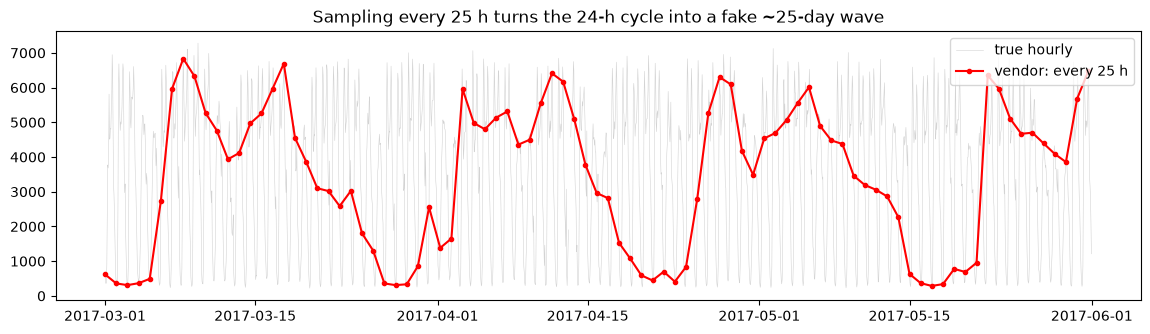

In [7]:
# (given) What the vendor's data would look like for spring 2017
seg = tr["traffic_volume"].loc["2017-03-01":"2017-05-31"].asfreq("h").interpolate(limit=3)
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(seg.index, seg.values, c="lightgrey", lw=0.4, label="true hourly")
ax.plot(seg.index[::25], seg.values[::25], "-o", c="red", ms=3, label="vendor: every 25 h")
ax.set_title(f"Sampling every 25 h turns the 24-h cycle into a fake ~{apparent_period_25h/24:.0f}-day wave"); ax.legend(); plt.show()

**B2. A manager looks only at the vendor's 25-hour samples and says: *'Traffic rises and falls on a roughly 25-day cycle — let's schedule closures in the low phase.'* Explain what is really happening, using the words sampling rate, Nyquist and aliasing.**

 *Your answer:* The real pattern is the **24-hour** commute cycle. Sampling once every 25 h is a sampling rate of 1/25 per hour, which is far below the **Nyquist** requirement of more than 2 samples per cycle (an interval under 12 h). Each sample lands one hour later in the day than the last, so the samples slowly crawl through the daily cycle. That is **aliasing**: f_a = |1/24 − 1/25| = 1/600, which shows up as a fake 600-h ≈ 25-day wave. The "low phase" is just the days when the sample happened to fall at night, so there is no real slow cycle to schedule around.

**B3. What maximum sampling interval would you recommend to MnDOT? Would sampling exactly every 12 hours be safe? Justify briefly.**

*Your answer:* Nyquist sets a hard limit of **less than 12 h**, but in practice I'd keep **hourly** sampling (or at most every 2–3 h). The commute peaks are sharp and only last a couple of hours, so the signal also has 12-h and 8-h harmonics that need finer sampling. Exactly 12 h is **not safe**. With exactly 2 samples per cycle you always hit the same two phases (e.g. 3 am and 3 pm), so the measured amplitude depends entirely on where you start, and you could miss the peaks completely.

---
## Part C — Aggregation and smoothing (5 min) *(slides 26–28)*
The engineers want a clean view of **2017**.

💻 **C1.** Compute:
- `daily`: **daily total** vehicles in 2017 (use `min_count=1`, so days with no data become NaN, not 0)
- `ma7_centred`: a **7-day centred** moving average of `daily`
- `ma7_trailing`: a **7-day trailing** moving average (the default `.rolling`)
- `points_per_pixel`: if every **hourly** row of 2017 were plotted on a **1000-pixel**-wide chart

In [8]:
daily = tr["traffic_volume"].loc["2017"].resample("D").sum(min_count=1)         # TODO
ma7_centred = daily.rolling(7, center=True).mean()      # TODO
ma7_trailing = daily.rolling(7).mean()      # TODO
points_per_pixel = len(tr.loc["2017"]) / 1000  # TODO

check_C(daily, ma7_centred, ma7_trailing, points_per_pixel)

✅ Part C correct — hourly 2017 on 1000 px = 8.7 points per pixel.


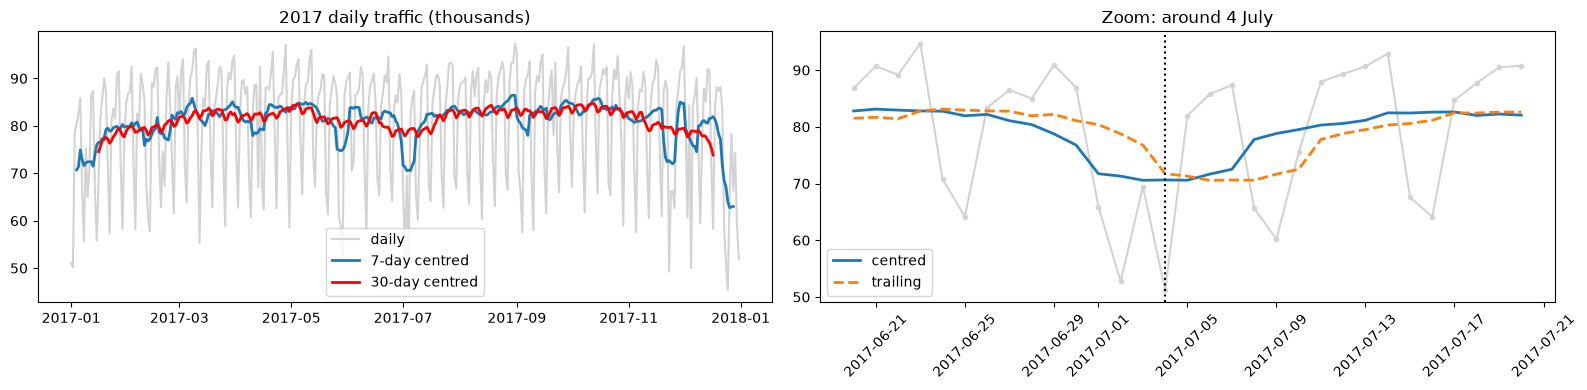

In [9]:
# (given)
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(daily.index, daily / 1e3, c="lightgrey", label="daily"); ax[0].plot(ma7_centred.index, ma7_centred / 1e3, lw=2, label="7-day centred")
ax[0].plot(daily.index, daily.rolling(30, center=True).mean() / 1e3, lw=2, c="red", label="30-day centred"); ax[0].legend(); ax[0].set_title("2017 daily traffic (thousands)")
z = slice("2017-06-20", "2017-07-20")
ax[1].plot(daily.loc[z] / 1e3, "o-", c="lightgrey", ms=3); ax[1].plot(ma7_centred.loc[z] / 1e3, lw=2, label="centred"); ax[1].plot(ma7_trailing.loc[z] / 1e3, lw=2, ls="--", label="trailing")
ax[1].axvline(pd.Timestamp("2017-07-04"), c="k", ls=":"); ax[1].legend(); ax[1].set_title("Zoom: around 4 July"); ax[1].tick_params(axis="x", rotation=45); plt.tight_layout(); plt.show()

**C2. In the zoom, the trailing average dips *after* 4 July while the centred one dips *around* it. How many days does a 7-day trailing average lag, and why does that matter to someone reading the chart?**

 *Your answer:* A trailing 7-day mean at day *t* averages days *t−6 … t*, so its centre sits **(7−1)/2 = 3 days** behind and the curve lags by about 3 days. A reader would place the holiday dip around 7 July and see it smeared over the following week, so they'd misjudge *when* the event happened and how long it lasted. A centred window keeps the dip on the right date. The trade-off is that it can't be computed for the last 3 days, which matters only for real-time monitoring.

**C3. The engineers care about which *day of the week* is quietest. Which is the right view: raw daily, 7-day MA, or 30-day MA? What does each larger window hide? Also interpret your `points_per_pixel` value.**

*Your answer:* **Raw daily** is the right view. The weekday/weekend difference is a 7-day cycle, and a 7-day window contains exactly one of each weekday, so the **7-day MA cancels the weekly pattern** completely and leaves only the trend. The **30-day MA** hides the weekly cycle and also single-day events like holidays, so only the seasonal shape is left. My `points_per_pixel` is about **8–9**, meaning roughly 8–9 hourly values share each pixel column. They overplot into a solid band, so hourly 2017 data on a 1000-px chart needs to be aggregated or zoomed into before it can be read.

---
## Part D — Filtering and events: choose the closure hour (4 min) *(slides 24, 29)*
Crews can only work in **daytime**, starting between **9:00 and 15:00**. Find the **quietest start hour on a normal weekday**, and compare it with holidays.

💻 **D1.** Compute:
- `weekday_profile`: mean traffic **by hour (0–23)** for **Mon–Fri non-holiday** rows
- `holiday_profile`: mean traffic by hour for rows where `holiday_day != "None"`
- `best_closure_hour`: the hour between **9 and 15** (inclusive) where `weekday_profile` is lowest

In [10]:
wk = tr[(tr.index.dayofweek < 5) & (tr.holiday_day == "None")]            # TODO: filter tr — weekdays (tr.index.dayofweek < 5) AND not a holiday
weekday_profile = wk.groupby(wk.index.hour)["traffic_volume"].mean()    # TODO: wk.groupby(wk.index.hour)["traffic_volume"].mean()

hol = tr[tr.holiday_day != "None"]                # TODO: filter holiday rows
holiday_profile = hol.groupby(hol.index.hour)["traffic_volume"].mean()   # TODO

best_closure_hour = int(weekday_profile.loc[9:15].idxmin())  # TODO: int(...)

check_D(weekday_profile, holiday_profile, best_closure_hour)

✅ Part D correct — the quietest daytime start hour on normal weekdays is 10:00.


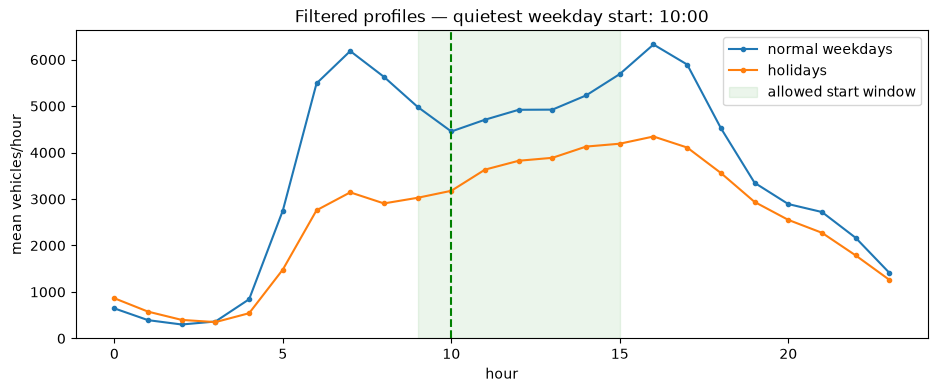

In [11]:
# (given)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weekday_profile.index, weekday_profile.values, "-o", ms=3, label="normal weekdays")
ax.plot(holiday_profile.index, holiday_profile.values, "-o", ms=3, label="holidays")
ax.axvspan(9, 15, color="green", alpha=0.08, label="allowed start window"); ax.axvline(best_closure_hour, c="green", ls="--")
ax.set(xlabel="hour", ylabel="mean vehicles/hour", title=f"Filtered profiles — quietest weekday start: {best_closure_hour}:00"); ax.legend(); plt.show()

**D2. You *filtered* (kept only weekday non-holiday rows) and then *aggregated* (mean per hour). What does each step keep and what does it hide? Name one risk of relying only on the mean profile for the closure decision.**

 *Your answer:* **Filtering** keeps full detail for normal weekdays but hides weekends and holidays, which behave differently (holidays are much quieter, as the second curve shows). **Aggregation** collapses hundreds of days into one value per hour. That gives a clean profile but hides the **spread**: day-to-day variation, seasonal differences, bad weather, incidents and outliers. The risk is that the mean can be lowest at the chosen hour while individual days, such as summer Fridays or snow days, are much busier. I'd also check the IQR or upper quantiles and a per-month profile before fixing the closure time.

---
## Part E — Design the animated *Traffic Pulse* for the lobby screen (6 min) 
**Design brief:** the screen animates **24 hourly states** of a typical weekday. Each hour is shown for **0.75 s** at **30 fps**, with a smooth transition between hours.

💻 **E1.** Implement and compute:
- `frame_budget_ms(fps)`: milliseconds available per frame
- `smoothstep(u)`: the ease-in-out function $3u^2-2u^3$
- `n_frames`, `duration_s`: for the brief above
- `compression`: seconds of **data** per second of **animation** (one hour of data per 0.75 s)

In [12]:
def frame_budget_ms(fps):
    return 1000 / fps      # TODO

def smoothstep(u):
    return 3 * u**2 - 2 * u**3    # TODO

hold_s, fps = 0.75, 30
duration_s  = 24 * hold_s                  # TODO
n_frames    = int(round(duration_s * fps)) # TODO (int)
compression = 3600 / hold_s                # TODO

💻 **E2.** A second version shows how the **weekday profile changes month by month** in 2017. Build `fig` with `px.bar` using **`animation_frame="Month"`**, and **fix the y-axis** so bars stay comparable across frames (congruence).

In [13]:
# (given) monthly weekday profiles for 2017
wk17 = wk.loc["2017"]
mp = wk17.groupby([wk17.index.month.rename("month"), wk17.index.hour.rename("hour")])["traffic_volume"].mean().rename("vehicles").reset_index()
mp["Month"] = mp["month"].map(lambda m: calendar.month_abbr[m])
MONTHS = [calendar.month_abbr[i] for i in range(1, 13)]
mp.head()

,month,hour,vehicles,Month
0,1,0,605.65,Jan
1,1,1,391.60,Jan
2,1,2,315.00,Jan
3,1,3,387.95,Jan
4,1,4,864.70,Jan


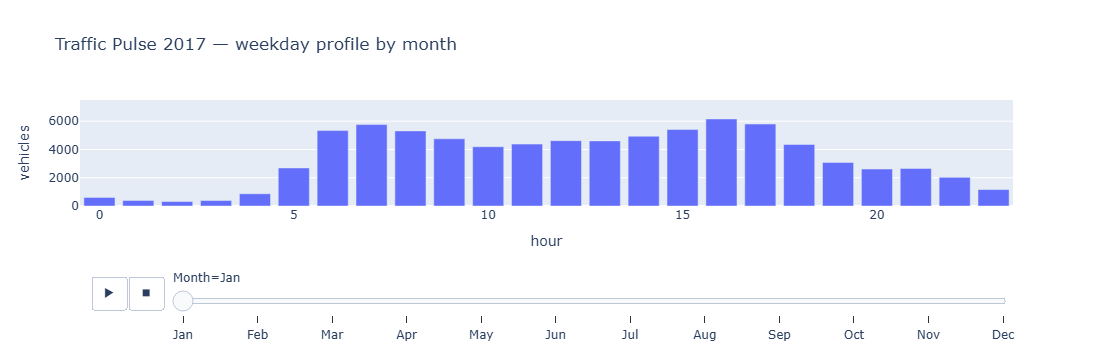

✅ Part E correct — 540 frames, 18 s, 4800:1, fixed axis, 12 frames.


In [15]:
fig = px.bar(mp, x="hour", y="vehicles",
             animation_frame="Month",
             category_orders={"Month": MONTHS},
             range_y=[0, 7500],
             title="Traffic Pulse 2017 — weekday profile by month")
fig.show()

check_E(frame_budget_ms, smoothstep, n_frames, duration_s, compression, fig)

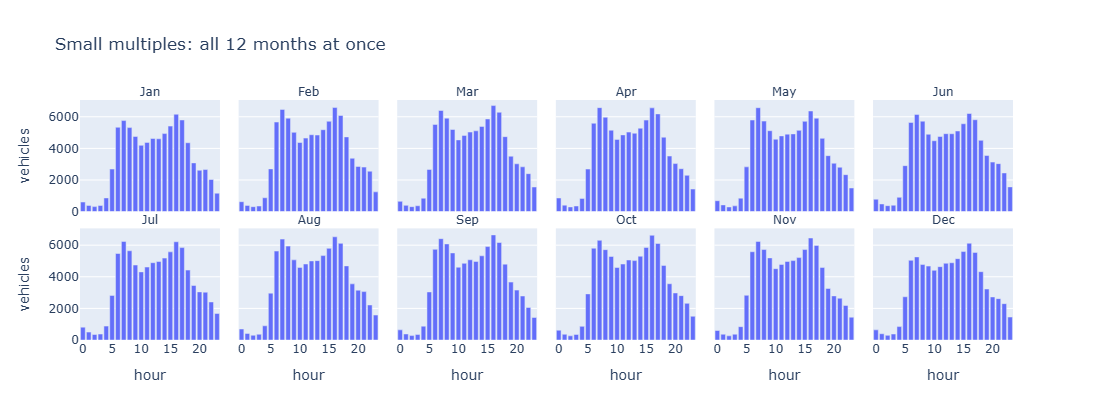

In [16]:
# (given) The SAME data as small multiples — compare with the animation
fig2 = px.bar(mp, x="hour", y="vehicles", facet_col="Month", facet_col_wrap=6, category_orders={"Month": MONTHS}, height=420,
              title="Small multiples: all 12 months at once")
fig2.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1])); fig2.show()

**E3. Play the animation and try to answer: *In which month is the 17:00 peak lowest?* Then answer it with the small multiples. Which was faster and more certain, and why? Use the terms working memory and 'eyes beat memory'.**

*Your answer:* With the animation I had to remember the 17:00 bar height from earlier frames while new ones replaced them. **Working memory** only holds a few items, so comparing 12 months meant replaying and pausing, and I still wasn't fully sure. With the **small multiples** all 12 panels are on screen at once, so my eyes can jump between them and compare the bars directly. That was faster and more certain, which is the **"eyes beat memory"** idea: comparing things you can see is cheaper than comparing against things you have to remember.

**E4. What would go wrong if you left out `range_y` (letting each frame auto-scale)? Which Heer & Robertson principle does that violate?**

*Your answer:* Each frame would rescale its y-axis to its own maximum, so the same bar height would mean a different number of vehicles in each month. A real drop in traffic could look like no change, and a quiet month could look as "full" as a busy one, so the motion between frames would be misleading. This breaks **congruence**: the visual change should correspond to the change in the data. In Heer & Robertson's terms, it fails to *maintain valid data graphics during transitions* and keep the mapping consistent.

**E5. Why use smoothstep (slow-in/slow-out) between hours instead of linear motion or a jump cut? Refer to your `smoothstep(0.25)` value and the per-frame jumps at the start and end.**

 *Your answer:* `smoothstep(0.25) = 0.156`, so a quarter of the way through the transition only about 16% of the change has happened (linear would be 25%). The slope of 3u² − 2u³ is **0 at u = 0 and u = 1**, so the first and last frames of each transition move only tiny amounts, and most of the motion happens in the middle (peak speed 1.5× linear). The bars ease out of one state and settle into the next, which makes the motion easy to track and the end state easy to read. Linear motion starts and stops abruptly, and a jump cut gives no continuity at all, so viewers lose track of which bar changed (change blindness).

---
## Part F — Final recommendation (3 min) *(slides 15–16, 33–38)*
Write your recommendation to your manager.

**F1. For the **road-works engineers**: which visualization(s) should they get, and should they be animated? Name at least two idioms from the lecture and justify.**

 *Your answer:* They should get **static** views, not animation, because they need precise comparison and lookup. I'd give them (1) a **line chart of the filtered weekday hourly profile with an IQR band**, with the holiday profile overlaid and the 9–15 window shaded, since position on a common scale is the most accurate channel; (2) a **day-of-week × hour heatmap** to spot the quiet slots across the whole week; and (3) **small multiples by month** to check that the best hour holds across seasons. An **overview + detail** line chart with a range slider lets them drill into specific dates. Animation would force them to compare from memory.

**F2. For the **public lobby screen**: animation is acceptable here. Give three concrete design rules you'd apply (timing, fps, scales, labels, playback) so the public actually perceives the change.**

 *Your answer:* 
1. **Timing:** hold each hour for about 0.75 s with a short smoothstep transition, and render at a steady 30 fps (within the 33 ms frame budget) so the motion looks smooth and doesn't stutter.
2. **Stable scales:** fix the y-axis (0–7500) and the colour scale for the whole loop so bar heights stay comparable between frames.
3. **Labels and playback:** show a large, always-visible clock or month label plus a progress bar, highlight the current/peak bar, and pause for a couple of seconds at the end before looping so viewers can reset and catch up.

**F3. A viewer watching the lobby animation fails to notice that the evening peak disappears in one month. What is this phenomenon, and name two ways to reduce it.**

 *Your answer:* This is **change blindness**: people often miss even large changes when they happen during motion or across a frame change, because attention is somewhere else. To reduce it: (1) **highlight the change**, for example by flashing or outlining the bar or adding a callout like "evening peak missing in <month>", and pause briefly on that frame; (2) keep a **reference**, such as a faint ghost of the average profile or the previous frame behind the bars, so the drop is visible against it. Slowing the transitions and showing a small-multiples summary at the end also helps.

---
## Score — run this cell

In [17]:
summary()

Part A: ✅
Part B: ✅
Part C: ✅
Part D: ✅
Part E: ✅
Coding score: 5/5   (+ reflection questions, graded by instructor)
